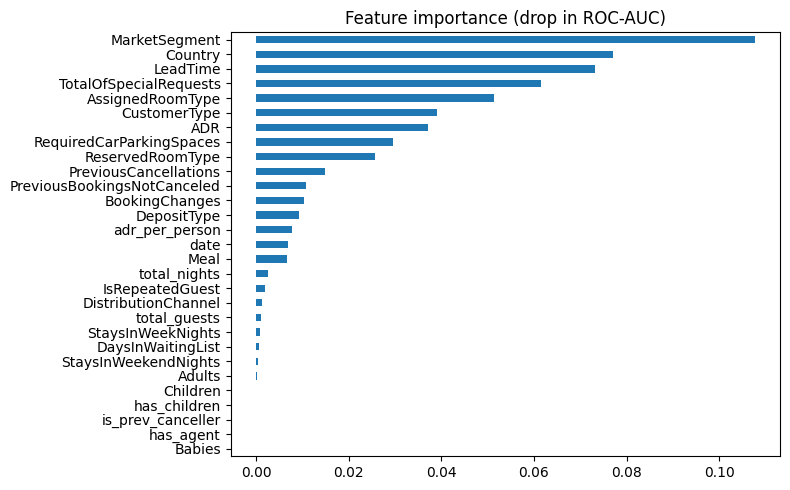

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

PATH = r"C:\Users\salma\Documents\GitHub\Machine-Learning\src\hotel_booking\classification\H2_classification.csv"
df = pd.read_csv(PATH)
y = df["IsCanceled"]
X = df.drop(columns=["IsCanceled"])
    
# safety: remove raw date columns if they are in the file
#X = X.drop(columns=[c for c in ["date", "arrival_date"] if c in X.columns])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])),
    ("clf", HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=500, max_leaf_nodes=63,
        l2_regularization=1.0, early_stopping=True, random_state=42)),
])
model.fit(X_train, y_train)

# quick importance plot
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                              n_repeats=3, n_jobs=-1, random_state=42)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(8, 5), title="Feature importance (drop in ROC-AUC)")
plt.tight_layout()
plt.show()